# Goal Room DQN

Train a deep Q network to reach the Woodsman's Hut.

## Settings

In [1]:
goal_room = "woodsman's hut"  # the goal room we're trying to reach
training_episodes = 200
max_episode_steps = 50
eval_interval = 10
eval_episodes = 3
seed = 7
learning_rate = 0.001
discount = 0.95  # γ / gamma, each step away from the reward scales by this amount

## Imports

In [2]:
from copy import deepcopy
from time import perf_counter

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

from mudgym import make_env
from mudgym.notebooks import show_ansi, show_episode_transcript, show_space, show_table

## Environment

We're using MudGym's `cheats` observation mode, which gives us the current room's index as `room_id_index` and its open exits as `available_exits`. For the action space we're using `directions` which gives us a smaller discrete action space of the 14 movement directions.

In [3]:
env = make_env(observation="cheats", actions="directions")

In [4]:
show_space(env.observation_space)

asleep,"Discrete(2, dtype=int8)"
available_exit_names,Sequence(Text(max_length=9))
available_exits,MultiBinary(14)
dark,"Discrete(2, dtype=int8)"
fighting,"Discrete(2, dtype=int8)"
flags,MultiBinary(4)
gifted,"Discrete(2, dtype=int8)"
glowing,"Discrete(2, dtype=int8)"
here,Sequence(Text(max_length=96))
inventory,Sequence(Text(max_length=17))
points,"Box(0, 204800, (), int32)"


In [5]:
# the command the env sends to the game for each action, kept before the reward wrapper hides it
commands = env.commands
print(env.action_space)
show_table(
    [{"Action": action, "Command": command} for action, command in enumerate(commands)],
    mono_columns=("Command",),
)

Discrete(14)


0,move north
1,move east
2,move south
3,move west
4,move northeast
5,move southeast
6,move southwest
7,move northwest
8,move up
9,move down
10,move in


We use a wrapper to modify our env to reward the agent for reaching our desired goal room with a reward of +1 and we ignore the usual rewards from the game. We also add a small negative step penalty reward of -0.01 for all other steps to encourage shorter routes to the goal.

In [6]:
class GoalRoomReward(gym.Wrapper):
    def __init__(self, env, goal_room, success_reward=1.0, step_penalty=-0.01):
        super().__init__(env)
        self.goal_room = goal_room
        self.success_reward = success_reward
        self.step_penalty = step_penalty

    def step(self, action):
        observation, _, terminated, truncated, info = self.env.step(action)
        success = observation["room_name"] == self.goal_room
        reward = self.success_reward if success else self.step_penalty
        info = {**info, "is_success": success}
        return observation, reward, terminated or success, truncated, info

In [7]:
# wrap our env in the goal reward wrapper
env = GoalRoomReward(env, goal_room=goal_room)

# have a look at where we start
sample_observation, sample_info = env.reset(seed=seed)
display(show_ansi(sample_info["render_bytes"]))
print("Room ID:", sample_observation["room_id"])
print("Available exits:", ", ".join(sample_observation["available_exit_names"]))

<HTML output, 1286 characters>

Room ID: mostart
Available exits: north, east, south, west, northeast, southeast, southwest, northwest, out, swampward


## Model

Our network takes a room ID index and returns a Q value for each direction.

We look up the current room in a 64 dim embedding layer, then pass the output through two linear + ReLU layers, followed by a final linear layer outputting one Q value per direction action.

```text
room
  |
  v
embedding        a 64 dim embedding representing this room
  |
  v
linear + ReLU    64 -> 64
  |
  v
linear + ReLU    64 -> 64
  |
  v
linear           64 -> 14
  |
  v
Q values         one per direction
```

In [8]:
class QNetwork:
    """A room embedding -> two ReLU hidden layers -> linear Q value head."""

    def __init__(
        self,
        room_count: int,
        action_count: int,
        *,
        seed: int = 7,
        embedding_dim: int = 64,
        hidden_dim: int = 64,
    ) -> None:
        rng = np.random.default_rng(seed)
        self.params = {
            "embedding": rng.standard_normal((room_count, embedding_dim)).astype(np.float32),
        }

        # small starting weights
        for layer, (fan_in, fan_out) in enumerate(
            [(embedding_dim, hidden_dim), (hidden_dim, hidden_dim), (hidden_dim, action_count)],
            start=1,
        ):
            bound = 1.0 / np.sqrt(fan_in)
            self.params[f"w{layer}"] = rng.uniform(-bound, bound, (fan_in, fan_out)).astype(np.float32)
            self.params[f"b{layer}"] = rng.uniform(-bound, bound, fan_out).astype(np.float32)

    def forward_with_activations(self, room_indices):
        """We're not really using a framework, so this hands back the activations for the backward pass too."""
        p = self.params

        # look up the room embedding
        x = p["embedding"][room_indices]
        h1 = np.maximum(x @ p["w1"] + p["b1"], 0)
        h2 = np.maximum(h1 @ p["w2"] + p["b2"], 0)
        return h2 @ p["w3"] + p["b3"], (x, h1, h2)

    def __call__(self, room_indices) -> np.ndarray:
        """
        Just doing this so it looks like PyTorch.

        Returns Q values with shape (B, A) for a batch of B room indices.
        """
        return self.forward_with_activations(room_indices)[0]

    def loss_and_gradients(self, room_indices, actions, targets):
        """Smooth L1 loss on the moves we actually took, and its gradients. Doesn't update anything."""
        q, (x, h1, h2) = self.forward_with_activations(room_indices)
        rows = np.arange(len(room_indices))
        error = q[rows, actions] - targets
        absolute = np.abs(error)
        loss = float(np.where(absolute < 1, 0.5 * error**2, absolute - 0.5).mean())

        # only the moves we took get a gradient, but the weights are shared so the other Q values still shift
        dq = np.zeros_like(q)
        dq[rows, actions] = np.clip(error, -1, 1) / len(room_indices)

        # backprop by hand, from the head back to the embedding
        p = self.params
        grads = {"w3": h2.T @ dq, "b3": dq.sum(axis=0)}
        dh2 = (dq @ p["w3"].T) * (h2 > 0)
        grads.update(w2=h1.T @ dh2, b2=dh2.sum(axis=0))
        dh1 = (dh2 @ p["w2"].T) * (h1 > 0)
        grads.update(w1=x.T @ dh1, b1=dh1.sum(axis=0))
        grads["embedding"] = np.zeros_like(p["embedding"])
        # a batch can hit the same room more than once, add.at adds them all up where += would drop repeats
        np.add.at(grads["embedding"], room_indices, dh1 @ p["w1"].T)
        return loss, grads

    def copy_from(self, other: "QNetwork") -> None:
        """Copy the network parameters, not the optimiser state."""
        for name, value in self.params.items():
            np.copyto(value, other.params[name])

## Optimiser

Our optimiser nudges each weight in the direction to make the loss lower. It keeps running averages of each gradient and its square, which smooth the steps out and keep them a sensible size. Written out by hand here, using PyTorch's defaults.

In [9]:
class Adam:
    """Adam with bias correction."""

    def __init__(self, params, learning_rate: float = 1e-3) -> None:
        self.learning_rate = learning_rate
        self.m = {name: np.zeros_like(value) for name, value in params.items()}
        self.v = {name: np.zeros_like(value) for name, value in params.items()}
        self.steps = 0

    def step(self, params, grads) -> None:
        # stop loudly rather than quietly fill the network with NaNs
        if not all(np.isfinite(gradient).all() for gradient in grads.values()):
            raise FloatingPointError("Training stopped on a non-finite gradient.")
        self.steps += 1
        for name, value in params.items():
            gradient = grads[name]
            # running averages of the gradient and its square
            self.m[name] *= 0.9
            self.m[name] += 0.1 * gradient
            self.v[name] *= 0.999
            self.v[name] += 0.001 * gradient**2
            m_hat = self.m[name] / (1 - 0.9**self.steps)
            v_hat = self.v[name] / (1 - 0.999**self.steps)
            value -= self.learning_rate * m_hat / (np.sqrt(v_hat) + 1e-8)

## Replay and targets

Every move goes into a replay buffer, and the network learns from random batches of old moves rather than only the latest one.

The target is what a Q value should have been according to this batch of steps - the reward we got, plus an estimate of the best we can do from the next room. That guess comes from a second copy of the network, the target network, which we update less frequently. This makes training more stable, because what we're aiming at doesn't move with every update.

In [10]:
class ReplayBuffer:
    """A fixed size ring of past moves, kept as plain numbers."""

    def __init__(self, capacity: int, action_count: int) -> None:
        self.capacity = capacity
        self.size = 0
        self.position = 0
        self.columns = (
            np.empty(capacity, dtype=np.int32),  # state
            np.empty(capacity, dtype=np.int32),  # action
            np.empty(capacity, dtype=np.float32),  # reward
            np.empty(capacity, dtype=np.int32),  # next state
            np.empty((capacity, action_count), dtype=np.bool_),  # next exits
            np.empty(capacity, dtype=np.bool_),  # terminated, not truncated
        )

    def __len__(self) -> int:
        return self.size

    def add(self, state, action, reward, next_state, next_mask, terminated) -> None:
        for column, value in zip(self.columns, (state, action, reward, next_state, next_mask, terminated), strict=True):
            column[self.position] = value
        self.position = (self.position + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int, rng: np.random.Generator):
        indices = rng.choice(self.size, batch_size, replace=False)
        return tuple(column[indices] for column in self.columns)

In [11]:
def bellman_targets(target_network, rewards, next_states, next_masks, terminated, discount):
    """Reward plus the discounted best Q value from the next room, or just the reward if there's no next move."""
    targets = rewards.copy()
    # only look ahead where there's somewhere to go, so ended episodes never touch -inf
    continuing = ~terminated & next_masks.any(axis=1)
    q_next = target_network(next_states[continuing])
    targets[continuing] += discount * np.where(next_masks[continuing], q_next, -np.inf).max(axis=1)
    return targets

## Agent

We use an epsilon value to tell the agent to sometimes act randomly. It starts at 1, all random, and we gradually reduce this to 0.05 as training continues.

In [12]:
class DQNAgent:
    """Epsilon-greedy moves, replay updates and a target network."""

    def __init__(
        self,
        room_count: int,
        action_count: int,
        *,
        seed: int = 7,
        exploration_steps: int = 6_000,
        batch_size: int = 64,
        replay_capacity: int = 20_000,
        learning_starts: int = 128,
        train_every: int = 4,
        target_update_every: int = 20,
        discount: float = 0.95,
        learning_rate: float = 1e-3,
    ) -> None:
        self.network = QNetwork(room_count, action_count, seed=seed)
        self.target = deepcopy(self.network)
        self.optimizer = Adam(self.network.params, learning_rate)
        self.replay = ReplayBuffer(replay_capacity, action_count)
        policy_seed, replay_seed = np.random.SeedSequence(seed).spawn(2)
        self.policy_rng = np.random.default_rng(policy_seed)
        self.replay_rng = np.random.default_rng(replay_seed)
        self.action_count = action_count
        self.exploration_steps = exploration_steps
        self.batch_size = batch_size
        self.learning_starts = learning_starts
        self.train_every = train_every
        self.target_update_every = target_update_every
        self.discount = discount
        self.transitions = 0
        self.gradient_steps = 0

    @property
    def epsilon(self) -> float:
        """Falls from 1 to 0.05 over the first exploration_steps moves, then stays there."""
        return max(0.05, 1.0 - 0.95 * self.transitions / self.exploration_steps)

    def act(self, state: int, mask, *, explore: bool = True) -> int:
        if explore and self.policy_rng.random() < self.epsilon:
            return int(self.policy_rng.choice(np.flatnonzero(mask)))
        q = self.network([state])[0]
        if not np.isfinite(q).all():
            raise FloatingPointError("Training stopped on a non-finite Q value.")
        # best Q value among the open exits
        return int(np.argmax(np.where(mask, q, -np.inf)))

    def observe(self, state, action, reward, next_state, next_mask, terminated):
        """Store one move, and every few moves take a gradient step. Returns the loss when it trains."""
        self.replay.add(state, action, reward, next_state, next_mask, terminated)
        self.transitions += 1
        if len(self.replay) < self.learning_starts or self.transitions % self.train_every:
            return None
        states, actions, rewards, next_states, masks, terminals = self.replay.sample(self.batch_size, self.replay_rng)
        targets = bellman_targets(self.target, rewards, next_states, masks, terminals, self.discount)
        loss, grads = self.network.loss_and_gradients(states, actions, targets)
        self.optimizer.step(self.network.params, grads)
        self.gradient_steps += 1
        if self.gradient_steps % self.target_update_every == 0:
            self.target.copy_from(self.network)
        return loss

## Episodes

Each episode lasts up to `max_episode_steps` steps.

In [13]:
def play_episode(env, agent, *, seed, max_steps, learn=False, capture=False):
    """Reset the world and play up to max_steps moves."""
    observation, _ = env.reset(seed=seed)
    start_observation = deepcopy(observation)
    transitions = []
    episode_return = 0.0
    success = False
    steps = 0
    while steps < max_steps:
        mask = np.asarray(observation["available_exits"], dtype=np.bool_)
        if not mask.any():
            break  # nowhere to go
        state = observation["room_id_index"]
        action = agent.act(state, mask, explore=learn)
        # copy before stepping, the game can reuse observation arrays
        before = deepcopy(observation) if capture else None
        next_observation, reward, terminated, truncated, info = env.step(action)
        steps += 1
        episode_return += reward
        success = info["is_success"]

        if learn:
            # an ended episode has no room or exits to look ahead to
            next_mask = (
                np.zeros(agent.action_count, dtype=np.bool_)
                if terminated
                else np.asarray(next_observation["available_exits"], dtype=np.bool_)
            )
            next_state = next_observation["room_id_index"]
            # terminated only, running out of moves isn't the end of the world so it still looks ahead
            agent.observe(state, action, reward, next_state, next_mask, terminated)

        if capture:
            transitions.append(
                {
                    "step": steps,
                    "observation": before,
                    "action": action,
                    "reward": reward,
                    "next_observation": deepcopy(next_observation),
                    "info": deepcopy(info),
                }
            )
        observation = next_observation
        if terminated or truncated:
            break
    return {
        "steps": steps,
        "return": episode_return,
        "success": success,
        "start_observation": start_observation,
        "transitions": transitions,
    }


def play_in_fresh_world(agent, **options):
    """Play one episode, resetting with the same seed so it starts from the same fresh world."""
    return play_episode(env, agent, seed=seed, max_steps=max_episode_steps, **options)


def evaluate(agent, capture=False):
    """Greedy runs, no exploring and no learning."""
    return [play_in_fresh_world(agent, capture=capture) for episode in range(eval_episodes)]

## Fresh agent

A new agent with random weights, so to begin with it's just guessing. We check how it does before any learning. Rerun this cell and the ones below to start again from scratch.

In [14]:
agent = DQNAgent(
    env.observation_space["room_id_index"].n,
    env.action_space.n,
    seed=seed,
    # explore less and less over the first 60% of the move budget
    exploration_steps=int(0.6 * training_episodes * max_episode_steps),
    learning_rate=learning_rate,
    discount=discount,
)
print("Trainable parameters:", sum(value.size for value in agent.network.params.values()))

baseline_successes = sum(result["success"] for result in evaluate(agent))
print(f"Untrained greedy policy: {baseline_successes}/{eval_episodes} reached the goal")

Trainable parameters: 81358
Untrained greedy policy: 0/3 reached the goal


## Train

Every `eval_interval` episodes we check how it does greedily, and stop once every check reaches the hut, or when we run out of episodes. Reaching the hut is enough to stop, so there might still be a shorter route.

In [15]:
training_returns = []
eval_rows = []
started = perf_counter()
progress = display(HTML("Starting training…"), display_id=True)

for episode in range(1, training_episodes + 1):
    result = play_in_fresh_world(agent, learn=True)
    training_returns.append(result["return"])
    if episode % eval_interval == 0 or episode == training_episodes:
        checks = evaluate(agent)
        eval_rows.append(
            {
                "After episode": episode,
                "Goals reached": sum(check["success"] for check in checks),
                "Mean steps": float(np.mean([check["steps"] for check in checks])),
            }
        )
    progress.update(
        show_table(
            [
                {
                    "Episode": f"{episode}/{training_episodes}",
                    "Transitions": agent.transitions,
                    "Gradient updates": agent.gradient_steps,
                    "Epsilon": round(agent.epsilon, 3),
                    "Greedy goals": f"{eval_rows[-1]['Goals reached']}/{eval_episodes}" if eval_rows else "not yet",
                }
            ]
        )
    )
    # done once every greedy check makes it, as long as it's actually learnt something
    if eval_rows and eval_rows[-1]["Goals reached"] == eval_episodes and agent.gradient_steps:
        break

print(f"Training finished after {episode} episodes in {perf_counter() - started:.1f}s")

20/200,926,200,0.853,3/3


Training finished after 20 episodes in 3.6s


## Learning curves

On the left, return is the total reward for each training episode, so it goes up as the routes get shorter. It's still exploring, so expect some wobble. On the right, how many greedy checks reached the hut.

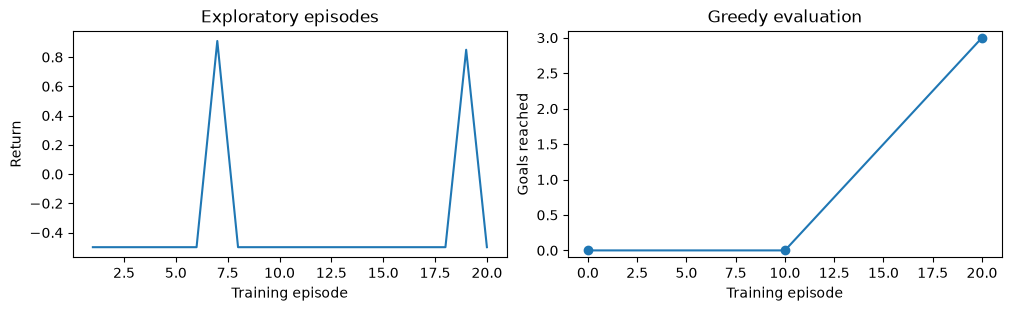

10,0,50
20,3,4


In [16]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].plot(range(1, len(training_returns) + 1), training_returns)
axes[0].set(xlabel="Training episode", ylabel="Return", title="Exploratory episodes")
axes[1].plot(
    [0] + [row["After episode"] for row in eval_rows],
    [baseline_successes] + [row["Goals reached"] for row in eval_rows],
    marker="o",
)
axes[1].set(
    xlabel="Training episode", ylabel="Goals reached", title="Greedy evaluation", ylim=(-0.1, eval_episodes + 0.1)
)
plt.show()
display(show_table(eval_rows))

## Evaluate

Our eval uses greedy action selection, always taking the highest Q value with no exploring.

In [17]:
final_evaluations = evaluate(agent, capture=True)
final_successes = sum(result["success"] for result in final_evaluations)
display(
    show_table(
        [
            {"Policy": "Untrained", "Goals reached": f"{baseline_successes}/{eval_episodes}"},
            {"Policy": "Trained", "Goals reached": f"{final_successes}/{eval_episodes}"},
        ]
    )
)

Untrained,0/3
Trained,3/3


## Route and Q values

The route and the Q values. Change `eval_episode_index` to look at another of the evaluation runs.

In [18]:
eval_episode_index = 0
selected_episode = final_evaluations[eval_episode_index]
route_rows = [
    {
        "Step": transition["step"],
        "From": transition["observation"]["room_name"],
        "Command": commands[transition["action"]],
        "To": transition["next_observation"].get("room_name", "episode ended"),
        "Reward": transition["reward"],
    }
    for transition in selected_episode["transitions"]
]
display(show_table(route_rows, mono_columns=("Command",)))

start_observation = selected_episode["start_observation"]
q_values = agent.network([start_observation["room_id_index"]])[0]
display(
    show_table(
        [
            {"Command": command, "Available": bool(available), "Q value": round(float(value), 4)}
            for command, available, value in zip(commands, start_observation["available_exits"], q_values)
        ]
    )
)

1,road opposite cottage,move swampward,vegetable garden,-0.01
2,vegetable garden,move south,east pasture,-0.01
3,east pasture,move north,in front of hut,-0.01
4,in front of hut,move south,woodsman's hut,1


move north,yes,0.3886
move east,yes,0.5581
move south,yes,0.5266
move west,yes,0.4114
move northeast,yes,0.3784
move southeast,yes,0.6492
move southwest,yes,0.395
move northwest,yes,0.3985
move up,no,0.4145
move down,no,0.6036
move in,no,0.3045


## Game output

In [19]:
show_episode_transcript(
    [
        {
            "command": commands[transition["action"]],
            "note": f"step {transition['step']} · reward {transition['reward']:+.2f}",
            "reply": transition["info"]["render_bytes"],
        }
        for transition in selected_episode["transitions"]
    ]
)

<HTML output, 5912 characters>